# Experimento de Speed-Up: Evaluacion Paralela del Fitness con Spark RDD

**Objetivo:** Primer experimento real del TFM. Medir sistematicamente el speed-up de la evaluacion paralela de fitness (GNB + 5-fold CV) con Spark RDD frente a la ejecucion secuencial.

**Variables del experimento:**
- **Tamano de poblacion ($P$):** 50, 100, 200, 500
- **Numero de particiones Spark:** 1, 2, 4, $N_{cores}$, $2 \times N_{cores}$

**Metricas:**
- Tiempo secuencial ($t_{seq}$) y paralelo ($t_{par}$) por evaluacion completa de la poblacion
- Speed-up: $S = t_{seq} / t_{par}$
- Eficiencia: $E = S / N_{cores} \times 100\%$
- Overhead de Spark: $t_{overhead} = t_{par} - t_{seq} / N_{particiones}$

**Dataset:** WDBC (569 muestras, 30 caracteristicas) — segun el diseno del GA (§6).

**Clasificador:** Gaussian Naive Bayes con 5-fold CV — segun el diseno del GA (§5.1).

---
## 1. Setup: Spark Session e Imports

In [1]:
import sys
sys.path.insert(0, '../src')

from spark_config import crear_sesion_spark, mostrar_info_spark, parar_spark
import numpy as np
import pandas as pd
import time
from datetime import datetime
from sklearn.datasets import load_breast_cancer
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print(f"Notebook iniciado: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Notebook iniciado: 2026-04-17 13:43:24


In [2]:
spark = crear_sesion_spark(
    app_name="TFM_SpeedUp_Experiment",
    master="local[*]",
    driver_memory="4g",
    executor_memory="4g",
    ui_port=4040,
    verbose=False
)

sc = spark.sparkContext
mostrar_info_spark(spark, ui_port=4040)

NUM_CORES = sc.defaultParallelism
print(f"\nCores disponibles para paralelismo: {NUM_CORES}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/04/17 13:43:25 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


🔥 INFORMACIÓN DE SPARK SESSION
✓ App Name: TFM_SpeedUp_Experiment
✓ Master: local[*]
✓ Spark Version: 3.5.0
✓ Python Version: 3.9
✓ Default Parallelism: 8
✓ Default Min Partitions: 2

🌐 SPARK WEB UI
📊 Accede en tu navegador a:
   👉 http://localhost:4040

   Opciones disponibles:
   - Jobs: Ver trabajos en ejecución/completados
   - Stages: Ver stages de cada job
   - Storage: Ver RDDs cacheados
   - Environment: Configuración de Spark
   - Executors: Estado de ejecutores


Cores disponibles para paralelismo: 8


---
## 2. Carga del Dataset WDBC (Wisconsin Diagnostic Breast Cancer)

El dataset tiene 30 caracteristicas numericas y una variable objetivo binaria (maligno/benigno). Las 30 caracteristicas corresponden exactamente a la longitud del cromosoma $D = 30$.

In [3]:
# Cargar dataset
dataset = load_breast_cancer()
X = dataset.data    # (569, 30)
y = dataset.target  # 0=maligno, 1=benigno
D = X.shape[1]      # 30 caracteristicas
feature_names = dataset.feature_names

print(f"Dataset: {dataset.DESCR.splitlines()[0]}")
print(f"Muestras: {X.shape[0]}")
print(f"Caracteristicas (D): {D}")
print(f"Clases: {dict(zip(dataset.target_names, np.bincount(y)))}")
print(f"\nPrimeras 5 caracteristicas: {list(feature_names[:5])}")

Dataset: .. _breast_cancer_dataset:
Muestras: 569
Caracteristicas (D): 30
Clases: {'malignant': 212, 'benign': 357}

Primeras 5 caracteristicas: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']


---
## 3. Funcion Fitness y Broadcast del Dataset

Segun la arquitectura Spark del TFM, los datos se envian a los workers via `sc.broadcast()` para evitar copias redundantes en cada tarea. La funcion fitness usa GNB con 5-fold CV:

$$\text{Fitness}(\mathbf{c}) = \alpha \cdot \text{Accuracy}_{CV5}(\mathbf{c}) - \beta \cdot \frac{|S|}{D}$$

In [4]:
ALPHA = 0.9
BETA = 0.1
CV_FOLDS = 5
P_INIT = 0.5

# Broadcast de los datos para Spark
X_bc = sc.broadcast(X)
y_bc = sc.broadcast(y)


def evaluar_fitness(cromosoma):
    """Evalua el fitness de un cromosoma usando GNB con validacion cruzada."""
    indices_activos = [i for i, gen in enumerate(cromosoma) if gen == 1]
    d = len(cromosoma)

    if len(indices_activos) == 0:
        return 0.0

    X_data = X_bc.value[:, indices_activos]
    y_data = y_bc.value

    gnb = GaussianNB()
    scores = cross_val_score(gnb, X_data, y_data, cv=CV_FOLDS, scoring='accuracy')
    accuracy = scores.mean()

    penalizacion = len(indices_activos) / d
    return round(ALPHA * accuracy - BETA * penalizacion, 6)


def generar_poblacion(P, D, p_init=0.5, seed=42):
    """Genera una poblacion de P cromosomas binarios de longitud D."""
    rng = np.random.RandomState(seed)
    return [list(rng.binomial(1, p_init, D)) for _ in range(P)]


# Verificacion rapida
test_pop = generar_poblacion(5, D)
test_fitness = evaluar_fitness(test_pop[0])
print(f"Verificacion: fitness de un individuo con {sum(test_pop[0])}/{D} genes = {test_fitness:.6f}")
print(f"Broadcast de X ({X.shape}) e y ({y.shape}) activo en {NUM_CORES} workers")

Verificacion: fitness de un individuo con 13/30 genes = 0.798134
Broadcast de X ((569, 30)) e y ((569,)) activo en 8 workers


---
## 4. Experimento 1: Speed-Up por Tamano de Poblacion

Fijamos las particiones a $N_{cores}$ (configuracion por defecto) y variamos el tamano de poblacion $P \in \{50, 100, 200, 500\}$. Para cada $P$, medimos el tiempo secuencial y paralelo de una evaluacion completa de la poblacion.

Se repite cada medicion $N_{rep} = 3$ veces para obtener la mediana (robusta ante outliers).

In [5]:
POBLACIONES = [50, 100, 200, 500]
N_REP = 3

resultados_exp1 = []

print(f"EXPERIMENTO 1: Speed-Up por Tamano de Poblacion")
print(f"Particiones fijas: {NUM_CORES} | Repeticiones: {N_REP}")
print(f"{'=' * 70}")

for P in POBLACIONES:
    poblacion = generar_poblacion(P, D)

    # Medicion secuencial (N_REP repeticiones)
    tiempos_seq = []
    for rep in range(N_REP):
        t0 = time.time()
        fitness_seq = [evaluar_fitness(ind) for ind in poblacion]
        tiempos_seq.append(time.time() - t0)

    # Medicion paralela (N_REP repeticiones)
    tiempos_par = []
    for rep in range(N_REP):
        rdd = sc.parallelize(poblacion, numSlices=NUM_CORES)
        t0 = time.time()
        fitness_par = rdd.map(evaluar_fitness).collect()
        tiempos_par.append(time.time() - t0)

    t_seq = np.median(tiempos_seq)
    t_par = np.median(tiempos_par)
    speedup = t_seq / t_par if t_par > 0 else 0
    eficiencia = speedup / NUM_CORES * 100

    resultados_exp1.append({
        'P': P,
        'particiones': NUM_CORES,
        't_seq_s': round(t_seq, 4),
        't_par_s': round(t_par, 4),
        'speedup': round(speedup, 2),
        'eficiencia_pct': round(eficiencia, 1),
        't_por_ind_seq_ms': round(t_seq / P * 1000, 2),
        't_por_ind_par_ms': round(t_par / P * 1000, 2),
    })

    print(f"  P={P:>4d} | t_seq={t_seq:.2f}s | t_par={t_par:.2f}s | "
          f"speedup={speedup:.2f}x | efic={eficiencia:.0f}%")

print(f"{'=' * 70}")

df_exp1 = pd.DataFrame(resultados_exp1)
print(f"\n{df_exp1.to_string(index=False)}")

EXPERIMENTO 1: Speed-Up por Tamano de Poblacion
Particiones fijas: 8 | Repeticiones: 3


  P=  50 | t_seq=0.10s | t_par=0.09s | speedup=1.18x | efic=15%
  P= 100 | t_seq=0.21s | t_par=0.07s | speedup=2.91x | efic=36%
  P= 200 | t_seq=0.42s | t_par=0.14s | speedup=3.07x | efic=38%
  P= 500 | t_seq=1.17s | t_par=0.29s | speedup=4.03x | efic=50%

  P  particiones  t_seq_s  t_par_s  speedup  eficiencia_pct  t_por_ind_seq_ms  t_por_ind_par_ms
 50            8   0.1003   0.0851     1.18            14.7              2.01              1.70
100            8   0.2116   0.0727     2.91            36.4              2.12              0.73
200            8   0.4241   0.1382     3.07            38.4              2.12              0.69
500            8   1.1735   0.2915     4.03            50.3              2.35              0.58


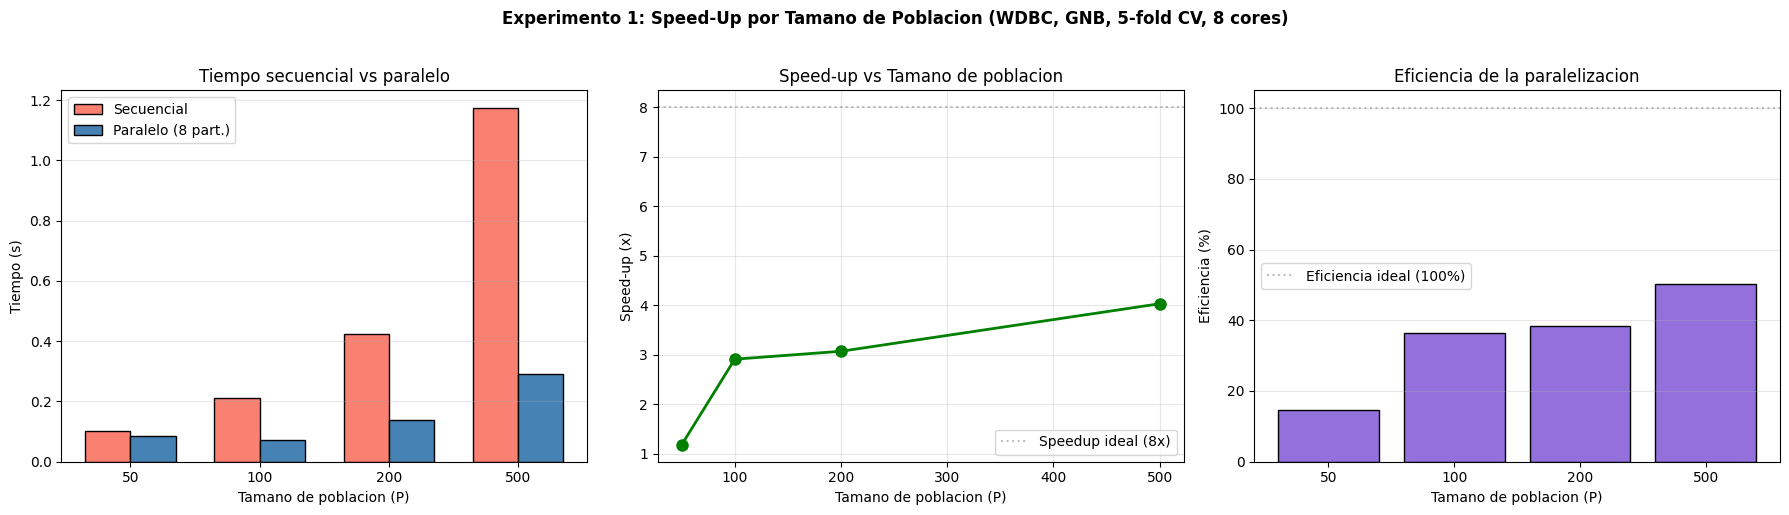

Grafico guardado en results/exp1_speedup_poblacion.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pobs = df_exp1['P'].values
t_seqs = df_exp1['t_seq_s'].values
t_pars = df_exp1['t_par_s'].values
speedups = df_exp1['speedup'].values

# Grafico 1: Tiempos secuencial vs paralelo
x = np.arange(len(pobs))
w = 0.35
axes[0].bar(x - w/2, t_seqs, w, label='Secuencial', color='salmon', edgecolor='black')
axes[0].bar(x + w/2, t_pars, w, label=f'Paralelo ({NUM_CORES} part.)', color='steelblue', edgecolor='black')
axes[0].set_xticks(x)
axes[0].set_xticklabels(pobs)
axes[0].set_xlabel('Tamano de poblacion (P)')
axes[0].set_ylabel('Tiempo (s)')
axes[0].set_title('Tiempo secuencial vs paralelo')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Grafico 2: Speed-up vs Poblacion
axes[1].plot(pobs, speedups, 'o-', color='green', linewidth=2, markersize=8)
axes[1].axhline(y=NUM_CORES, color='gray', linestyle=':', alpha=0.5, label=f'Speedup ideal ({NUM_CORES}x)')
axes[1].set_xlabel('Tamano de poblacion (P)')
axes[1].set_ylabel('Speed-up (x)')
axes[1].set_title('Speed-up vs Tamano de poblacion')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Grafico 3: Eficiencia vs Poblacion
efics = df_exp1['eficiencia_pct'].values
axes[2].bar(x, efics, color='mediumpurple', edgecolor='black')
axes[2].axhline(y=100, color='gray', linestyle=':', alpha=0.5, label='Eficiencia ideal (100%)')
axes[2].set_xticks(x)
axes[2].set_xticklabels(pobs)
axes[2].set_xlabel('Tamano de poblacion (P)')
axes[2].set_ylabel('Eficiencia (%)')
axes[2].set_title('Eficiencia de la paralelizacion')
axes[2].legend()
axes[2].grid(True, alpha=0.3, axis='y')

plt.suptitle(f'Experimento 1: Speed-Up por Tamano de Poblacion (WDBC, GNB, {CV_FOLDS}-fold CV, {NUM_CORES} cores)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/exp1_speedup_poblacion.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico guardado en results/exp1_speedup_poblacion.png")

---
## 5. Experimento 2: Speed-Up por Numero de Particiones

Fijamos $P = 100$ (parametro de referencia del diseno del GA para WDBC, §6) y variamos el numero de particiones Spark: $\{1, 2, 4, N_{cores}, 2 \times N_{cores}\}$.

In [7]:
P_FIJO = 100
PARTICIONES = sorted(set([1, 2, 4, NUM_CORES, NUM_CORES * 2]))

poblacion = generar_poblacion(P_FIJO, D)

# Baseline secuencial (una vez, N_REP repeticiones)
tiempos_seq_base = []
for rep in range(N_REP):
    t0 = time.time()
    [evaluar_fitness(ind) for ind in poblacion]
    tiempos_seq_base.append(time.time() - t0)
t_seq_base = np.median(tiempos_seq_base)

resultados_exp2 = []

print(f"EXPERIMENTO 2: Speed-Up por Numero de Particiones")
print(f"Poblacion fija: P={P_FIJO} | Baseline secuencial: {t_seq_base:.2f}s")
print(f"{'=' * 70}")

for n_part in PARTICIONES:
    tiempos = []
    for rep in range(N_REP):
        rdd = sc.parallelize(poblacion, numSlices=n_part)
        t0 = time.time()
        rdd.map(evaluar_fitness).collect()
        tiempos.append(time.time() - t0)

    t_par = np.median(tiempos)
    speedup = t_seq_base / t_par if t_par > 0 else 0
    eficiencia = speedup / NUM_CORES * 100
    overhead = t_par - (t_seq_base / n_part)

    resultados_exp2.append({
        'particiones': n_part,
        'P': P_FIJO,
        't_seq_s': round(t_seq_base, 4),
        't_par_s': round(t_par, 4),
        'speedup': round(speedup, 2),
        'eficiencia_pct': round(eficiencia, 1),
        'overhead_s': round(max(overhead, 0), 4),
    })

    print(f"  Part={n_part:>2d} | t_par={t_par:.2f}s | "
          f"speedup={speedup:.2f}x | efic={eficiencia:.0f}% | "
          f"overhead={max(overhead, 0):.3f}s")

print(f"{'=' * 70}")

df_exp2 = pd.DataFrame(resultados_exp2)
print(f"\n{df_exp2.to_string(index=False)}")

EXPERIMENTO 2: Speed-Up por Numero de Particiones
Poblacion fija: P=100 | Baseline secuencial: 0.20s
  Part= 1 | t_par=0.21s | speedup=0.94x | efic=12% | overhead=0.012s
  Part= 2 | t_par=0.11s | speedup=1.73x | efic=22% | overhead=0.015s
  Part= 4 | t_par=0.07s | speedup=2.96x | efic=37% | overhead=0.017s
  Part= 8 | t_par=0.07s | speedup=2.99x | efic=37% | overhead=0.041s
  Part=16 | t_par=0.09s | speedup=2.21x | efic=28% | overhead=0.077s

 particiones   P  t_seq_s  t_par_s  speedup  eficiencia_pct  overhead_s
           1 100   0.1971   0.2087     0.94            11.8      0.0116
           2 100   0.1971   0.1140     1.73            21.6      0.0155
           4 100   0.1971   0.0665     2.96            37.0      0.0172
           8 100   0.1971   0.0660     2.99            37.3      0.0414
          16 100   0.1971   0.0890     2.21            27.7      0.0767


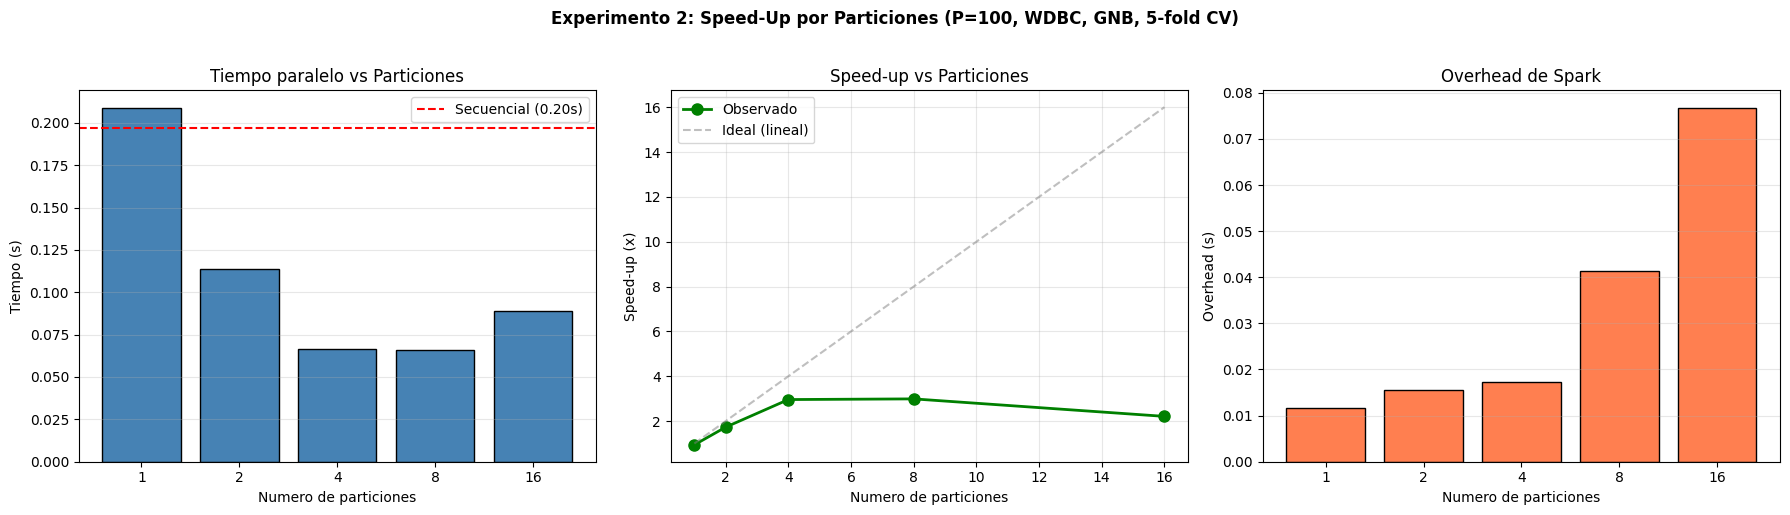

Grafico guardado en results/exp2_speedup_particiones.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

parts = df_exp2['particiones'].values
t_pars = df_exp2['t_par_s'].values
speedups = df_exp2['speedup'].values
overheads = df_exp2['overhead_s'].values

# Grafico 1: Tiempo vs Particiones
x = np.arange(len(parts))
axes[0].bar(x, t_pars, color='steelblue', edgecolor='black')
axes[0].axhline(y=t_seq_base, color='red', linestyle='--', label=f'Secuencial ({t_seq_base:.2f}s)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(parts)
axes[0].set_xlabel('Numero de particiones')
axes[0].set_ylabel('Tiempo (s)')
axes[0].set_title('Tiempo paralelo vs Particiones')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Grafico 2: Speed-up vs Particiones
axes[1].plot(parts, speedups, 'o-', color='green', linewidth=2, markersize=8, label='Observado')
axes[1].plot(parts, parts, '--', color='gray', alpha=0.5, label='Ideal (lineal)')
axes[1].set_xlabel('Numero de particiones')
axes[1].set_ylabel('Speed-up (x)')
axes[1].set_title('Speed-up vs Particiones')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Grafico 3: Overhead de Spark
axes[2].bar(x, overheads, color='coral', edgecolor='black')
axes[2].set_xticks(x)
axes[2].set_xticklabels(parts)
axes[2].set_xlabel('Numero de particiones')
axes[2].set_ylabel('Overhead (s)')
axes[2].set_title('Overhead de Spark')
axes[2].grid(True, alpha=0.3, axis='y')

plt.suptitle(f'Experimento 2: Speed-Up por Particiones (P={P_FIJO}, WDBC, GNB, {CV_FOLDS}-fold CV)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/exp2_speedup_particiones.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico guardado en results/exp2_speedup_particiones.png")

---
## 6. Experimento 3: Mapa Combinado Poblacion x Particiones

Cruzamos ambas variables para obtener una vista completa del speed-up. Se evalua cada combinacion $(P, N_{part})$ midiendo tiempo paralelo y speed-up.

In [9]:
resultados_exp3 = []

print(f"EXPERIMENTO 3: Mapa Combinado P x Particiones")
print(f"Poblaciones: {POBLACIONES} | Particiones: {PARTICIONES}")
print(f"{'=' * 70}")

for P in POBLACIONES:
    poblacion = generar_poblacion(P, D)

    # Baseline secuencial
    t0 = time.time()
    [evaluar_fitness(ind) for ind in poblacion]
    t_seq = time.time() - t0

    for n_part in PARTICIONES:
        rdd = sc.parallelize(poblacion, numSlices=n_part)
        t0 = time.time()
        rdd.map(evaluar_fitness).collect()
        t_par = time.time() - t0

        speedup = t_seq / t_par if t_par > 0 else 0

        resultados_exp3.append({
            'P': P,
            'particiones': n_part,
            't_seq_s': round(t_seq, 4),
            't_par_s': round(t_par, 4),
            'speedup': round(speedup, 2),
        })

    print(f"  P={P:>4d} completado")

print(f"{'=' * 70}")

df_exp3 = pd.DataFrame(resultados_exp3)
print(f"\n{df_exp3.to_string(index=False)}")

EXPERIMENTO 3: Mapa Combinado P x Particiones
Poblaciones: [50, 100, 200, 500] | Particiones: [1, 2, 4, 8, 16]
  P=  50 completado
  P= 100 completado
  P= 200 completado


  P= 500 completado

  P  particiones  t_seq_s  t_par_s  speedup
 50            1   0.1116   0.1096     1.02
 50            2   0.1116   0.0609     1.83
 50            4   0.1116   0.0431     2.59
 50            8   0.1116   0.0439     2.55
 50           16   0.1116   0.0727     1.54
100            1   0.2409   0.2124     1.13
100            2   0.2409   0.1134     2.12
100            4   0.2409   0.0660     3.65
100            8   0.2409   0.0609     3.95
100           16   0.2409   0.0817     2.95
200            1   0.4118   0.4338     0.95
200            2   0.4118   0.2221     1.85
200            4   0.4118   0.1262     3.26
200            8   0.4118   0.1018     4.05
200           16   0.4118   0.1305     3.16
500            1   0.9959   0.9989     1.00
500            2   0.9959   0.5315     1.87
500            4   0.9959   0.3014     3.30
500            8   0.9959   0.2354     4.23
500           16   0.9959   0.2717     3.67


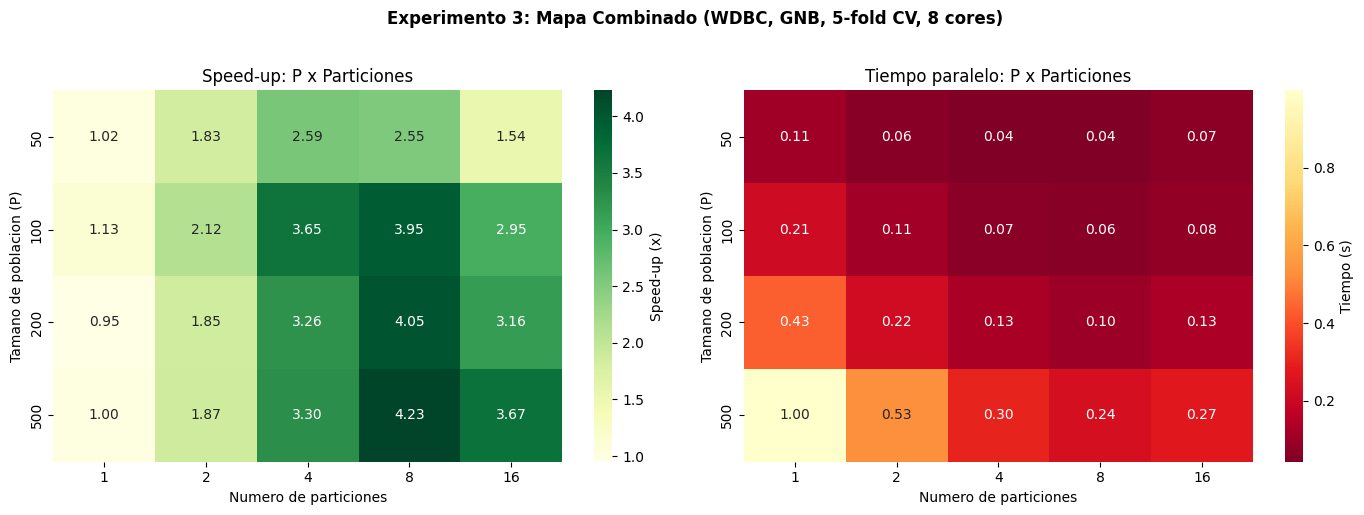

Grafico guardado en results/exp3_heatmap_speedup.png


In [10]:
import seaborn as sns

# Preparar matrices para heatmap
pivot_speedup = df_exp3.pivot(index='P', columns='particiones', values='speedup')
pivot_tiempo = df_exp3.pivot(index='P', columns='particiones', values='t_par_s')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap de speed-up
sns.heatmap(pivot_speedup, annot=True, fmt='.2f', cmap='YlGn', ax=axes[0],
            cbar_kws={'label': 'Speed-up (x)'})
axes[0].set_xlabel('Numero de particiones')
axes[0].set_ylabel('Tamano de poblacion (P)')
axes[0].set_title('Speed-up: P x Particiones')

# Heatmap de tiempo paralelo
sns.heatmap(pivot_tiempo, annot=True, fmt='.2f', cmap='YlOrRd_r', ax=axes[1],
            cbar_kws={'label': 'Tiempo (s)'})
axes[1].set_xlabel('Numero de particiones')
axes[1].set_ylabel('Tamano de poblacion (P)')
axes[1].set_title('Tiempo paralelo: P x Particiones')

plt.suptitle(f'Experimento 3: Mapa Combinado (WDBC, GNB, {CV_FOLDS}-fold CV, {NUM_CORES} cores)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/exp3_heatmap_speedup.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico guardado en results/exp3_heatmap_speedup.png")

---
## 7. Resumen y Exportacion de Resultados

In [11]:
# Resumen del experimento
print("=" * 60)
print("RESUMEN DEL EXPERIMENTO DE SPEED-UP")
print("=" * 60)

print(f"\nConfiguracion:")
print(f"  Dataset: WDBC (569 muestras, {D} caracteristicas)")
print(f"  Clasificador: GaussianNB")
print(f"  Validacion cruzada: {CV_FOLDS}-fold")
print(f"  Fitness: {ALPHA}*accuracy - {BETA}*(|S|/D)")
print(f"  Cores disponibles: {NUM_CORES}")
print(f"  Broadcast: X ({X.shape}) e y ({y.shape})")

print(f"\nExperimento 1 — Variacion de poblacion (part={NUM_CORES}):")
for _, r in df_exp1.iterrows():
    print(f"  P={int(r['P']):>4d}: t_seq={r['t_seq_s']:.2f}s, "
          f"t_par={r['t_par_s']:.2f}s, speedup={r['speedup']:.2f}x")

print(f"\nExperimento 2 — Variacion de particiones (P={P_FIJO}):")
for _, r in df_exp2.iterrows():
    print(f"  Part={int(r['particiones']):>2d}: t_par={r['t_par_s']:.2f}s, "
          f"speedup={r['speedup']:.2f}x, overhead={r['overhead_s']:.3f}s")

# Mejor configuracion del mapa combinado
mejor = df_exp3.loc[df_exp3['speedup'].idxmax()]
print(f"\nMejor speed-up observado: {mejor['speedup']:.2f}x")
print(f"  P={int(mejor['P'])}, particiones={int(mejor['particiones'])}")

# Exportar resultados a CSV
df_exp1.to_csv('../results/exp1_speedup_poblacion.csv', index=False)
df_exp2.to_csv('../results/exp2_speedup_particiones.csv', index=False)
df_exp3.to_csv('../results/exp3_speedup_combinado.csv', index=False)
print(f"\nResultados exportados a results/exp1_*, exp2_*, exp3_*.csv")
print("=" * 60)

RESUMEN DEL EXPERIMENTO DE SPEED-UP

Configuracion:
  Dataset: WDBC (569 muestras, 30 caracteristicas)
  Clasificador: GaussianNB
  Validacion cruzada: 5-fold
  Fitness: 0.9*accuracy - 0.1*(|S|/D)
  Cores disponibles: 8
  Broadcast: X ((569, 30)) e y ((569,))

Experimento 1 — Variacion de poblacion (part=8):
  P=  50: t_seq=0.10s, t_par=0.09s, speedup=1.18x
  P= 100: t_seq=0.21s, t_par=0.07s, speedup=2.91x
  P= 200: t_seq=0.42s, t_par=0.14s, speedup=3.07x
  P= 500: t_seq=1.17s, t_par=0.29s, speedup=4.03x

Experimento 2 — Variacion de particiones (P=100):
  Part= 1: t_par=0.21s, speedup=0.94x, overhead=0.012s
  Part= 2: t_par=0.11s, speedup=1.73x, overhead=0.015s
  Part= 4: t_par=0.07s, speedup=2.96x, overhead=0.017s
  Part= 8: t_par=0.07s, speedup=2.99x, overhead=0.041s
  Part=16: t_par=0.09s, speedup=2.21x, overhead=0.077s

Mejor speed-up observado: 4.23x
  P=500, particiones=8

Resultados exportados a results/exp1_*, exp2_*, exp3_*.csv


In [12]:
X_bc.destroy()
y_bc.destroy()
parar_spark(spark)
print(f"\nExperimento finalizado: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

✓ Spark session detenida

Experimento finalizado: 2026-04-17 13:43:45
